# Diagnóstico y limpieza de `heart.csv`: por qué no sirve para el Caso 5

**EP3 — Gestión de Proyectos de Datos (SCY1102).** Parte 1: Datos.

Este cuaderno revisa `heart.csv` problema por problema y deja con código la evidencia de cada uno.
Corrige lo que se puede corregir limpiando (duplicados, etiqueta invertida, faltantes enmascarados
y fuga de datos) y muestra lo que no se corrige: la población, la etiqueta y las variables que faltan.
Eso justifica el cambio a Framingham + ENS 2016-2017.

## Carpeta de trabajo
Se monta Drive y se trabaja en la carpeta del proyecto: lo que el cuaderno lee y guarda queda ahí. Antes, la carpeta compartida debe tener un acceso directo en Mi unidad.

In [1]:
import os

CARPETA = "/content/drive/MyDrive/Evalucion 3 y Examen"   # ruta del acceso directo en Mi unidad

try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(CARPETA)
except ModuleNotFoundError:
    pass   # fuera de Colab se usa la carpeta actual

os.makedirs("datos", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

print("Carpeta:", os.getcwd())
for f in ['datos/heart.csv']:
    print(f, "presente:", os.path.exists(f))

Mounted at /content/drive
Carpeta: /content/drive/.shortcut-targets-by-id/1Y-XrKLmj3y7vuHBzmQH9X-DvE-h6v7OV/Evalucion 3 y Examen
datos/heart.csv presente: True


In [2]:
import pandas as pd
import numpy as np

df_heart = pd.read_csv("datos/heart.csv")

df_heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
print("Filas y columnas:", df_heart .shape)
print("Nulos declarados:", df_heart .isna().sum().sum())
df_heart.describe().T[["min", "max", "mean"]].round(1)

Filas y columnas: (1025, 14)
Nulos declarados: 0


,min,max,mean
age,29.0,77.0,54.4
sex,0.0,1.0,0.7
cp,0.0,3.0,0.9
trestbps,94.0,200.0,131.6
chol,126.0,564.0,246.0
fbs,0.0,1.0,0.1
restecg,0.0,2.0,0.5
thalach,71.0,202.0,149.1
exang,0.0,1.0,0.3
oldpeak,0.0,6.2,1.1


A primera vista el archivo está limpio: 1.025 filas, 14 columnas, sin nulos y con rangos razonables. Las celdas siguientes muestran que esa impresión es falsa.

In [4]:
dup = df_heart.duplicated().sum()
print(f"Filas duplicadas: {dup} de {len(df_heart)} ({dup/len(df_heart ):.1%})")

# Cuántas veces aparece cada registro distinto
veces = df_heart.groupby(list(df_heart.columns)).size()
print("Veces que se repite cada registro:", veces.value_counts().sort_index().to_dict())

unicos = df_heart.drop_duplicates().reset_index(drop=True)
print("Pacientes únicos:", len(unicos))

Filas duplicadas: 723 de 1025 (70.5%)
Veces que se repite cada registro: {3: 187, 4: 114, 8: 1}
Pacientes únicos: 302


El 70,5 % de las filas son copias. Ningún registro aparece una sola vez: cada paciente está repetido 3, 4 u 8 veces, así que son duplicados y no coincidencias entre pacientes distintos. En realidad hay 302 pacientes, no 1.025. Como el archivo no trae identificador de paciente, solo se pueden detectar copias exactas: si dos filas del mismo paciente difieren en un valor, no hay forma de saberlo

In [5]:
senales = unicos.groupby("target").agg(
    pacientes=("age", "size"),
    edad_media=("age", "mean"),
    fc_maxima=("thalach", "mean"),
    depresion_ST=("oldpeak", "mean"),
    angina_esfuerzo=("exang", "mean"),
    vasos_obstruidos=("ca", lambda s: s.between(1, 3).mean()),
).round(2)
senales

,pacientes,edad_media,fc_maxima,depresion_ST,angina_esfuerzo,vasos_obstruidos
target,,,,,,
0,138,56.60,139.10,1.59,0.55,0.67
1,164,52.59,158.38,0.59,0.14,0.19


Las cinco señales apuntan al revés de la ficha: el grupo target = 0 es mayor, alcanza menor frecuencia máxima, tiene más depresión del ST, más angina de esfuerzo y más vasos obstruidos. Los enfermos son target = 0. La prevalencia corregida (45,7 %) coincide con la de la base Cleveland original (cerca de 46 %), y la inversión ya la reportaron otros usuarios del dataset (Burleigh, 2020).

In [6]:
unicos["enfermedad"] = 1 - unicos["target"]

sexo = {0: "Mujeres", 1: "Hombres"}
comparacion = pd.DataFrame({
    "Etiqueta original (%)": unicos.groupby("sex").target.mean().rename(sexo) * 100,
    "Etiqueta corregida (%)": unicos.groupby("sex").enfermedad.mean().rename(sexo) * 100,
}).round(1)
comparacion

,Etiqueta original (%),Etiqueta corregida (%)
sex,,
Mujeres,75.0,25.0
Hombres,44.7,55.3


Con la etiqueta original, las mujeres parecían tener 75 % de prevalencia y los hombres 44,7 %, lo contrario de lo que indica la epidemiología. Con la etiqueta corregida, los hombres tienen más del doble de prevalencia que las mujeres, que es lo esperable. Cualquier modelo entrenado con la etiqueta original habría aprendido a predecir la ausencia de enfermedad creyendo que predice la enfermedad.

In [7]:
ficha = {
    "cp":      {0: "angina típica", 1: "angina atípica", 2: "dolor no anginoso", 3: "asintomático"},
    "restecg": {0: "normal", 1: "anomalía ST-T", 2: "hipertrofia ventricular izq."},
    "slope":   {0: "ascendente", 1: "plana", 2: "descendente"},
    "ca":      {0: "0 vasos", 1: "1 vaso", 2: "2 vasos", 3: "3 vasos"},
    "thal":    {0: "normal", 1: "defecto fijo", 2: "defecto reversible"},
}

for col, codigos in ficha.items():
    reales = sorted(unicos[col].unique())
    sobran = [c for c in reales if c not in codigos]
    print(f"{col:<8} declarados: {sorted(codigos)}  reales: {reales}  no declarados: {sobran}")

cp       declarados: [0, 1, 2, 3]  reales: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]  no declarados: []
restecg  declarados: [0, 1, 2]  reales: [np.int64(0), np.int64(1), np.int64(2)]  no declarados: []
slope    declarados: [0, 1, 2]  reales: [np.int64(0), np.int64(1), np.int64(2)]  no declarados: []
ca       declarados: [0, 1, 2, 3]  reales: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]  no declarados: [np.int64(4)]
thal     declarados: [0, 1, 2]  reales: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]  no declarados: [np.int64(3)]


In [8]:
for col, codigos in ficha.items():
    t = unicos.groupby(col).agg(
        pacientes=("enfermedad", "size"),
        prevalencia=("enfermedad", "mean"),
    ).round(2)
    t["según la ficha"] = t.index.map(codigos).fillna("NO DECLARADO")
    print(f"\n{col}\n{t.to_string()}")


cp
    pacientes  prevalencia     según la ficha
cp                                           
0         143         0.73      angina típica
1          50         0.18     angina atípica
2          86         0.21  dolor no anginoso
3          23         0.30       asintomático

restecg
         pacientes  prevalencia                según la ficha
restecg                                                      
0              147         0.54                        normal
1              151         0.37                 anomalía ST-T
2                4         0.75  hipertrofia ventricular izq.

slope
       pacientes  prevalencia según la ficha
slope                                       
0             21         0.57     ascendente
1            140         0.65          plana
2            141         0.25    descendente

ca
    pacientes  prevalencia según la ficha
ca                                       
0         175         0.26        0 vasos
1          65         0.68         1 va

La ficha publicada no calza con los datos:

ca y thal tienen códigos que la ficha no declara (ca = 4, y thal con un cuarto valor).
cp = 0 tiene la prevalencia más alta (73 %). En la base original (Detrano et al., 1989), la prevalencia más alta es la del dolor asintomático, no la de la angina típica.
restecg = 2 tiene solo 4 pacientes. En la base original, la hipertrofia ventricular es una de las categorías más grandes y la que tiene 4 casos es la anomalía ST-T.
thal = 2 tiene la prevalencia más baja (22 %), lo que corresponde a un resultado normal y no a un defecto reversible.

Las categorías se podrían reinterpretar por sus frecuencias, pero eso sería una inferencia nuestra, no un dato. El diccionario de datos no es confiable, y es un problema de origen que la limpieza no corrige

In [9]:
print("Nulos declarados:", unicos.isna().sum().sum())
print("ca = 4:  ", (unicos.ca == 4).sum(), "registros")
print("thal = 0:", (unicos.thal == 0).sum(), "registros")

mascara = (unicos.ca == 4) | (unicos.thal == 0)
print("Registros afectados:", mascara.sum(), f"({mascara.mean():.1%})")
unicos[mascara]

Nulos declarados: 0
ca = 4:   4 registros
thal = 0: 2 registros
Registros afectados: 6 (2.0%)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,enfermedad
14,52,1,0,128,204,1,1,156,1,1.0,1,0,0,0,1
49,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1,0
108,52,1,2,138,223,0,1,169,0,0.0,2,4,2,1,0
212,53,0,2,128,216,0,0,115,0,0.0,2,0,0,1,0
227,43,1,0,132,247,1,0,143,1,0.1,1,4,3,0,1
269,58,1,1,125,220,0,1,144,0,0.4,1,4,3,1,0


In [10]:
limpio = unicos.copy()
limpio.loc[limpio.ca == 4, "ca"] = np.nan
limpio.loc[limpio.thal == 0, "thal"] = np.nan

print("Nulos reales:", limpio.isna().sum()[lambda s: s > 0].to_dict())

limpio = limpio.dropna().reset_index(drop=True)
print("Registros completos:", len(limpio))

Nulos reales: {'ca': 4, 'thal': 2}
Registros completos: 296


El archivo declara 0 nulos, pero ca y thal tienen códigos que no existen en la ficha. Coinciden exactamente con los faltantes de la base Cleveland original: 4 en ca y 2 en thal. Alguien los reemplazó por un número, así que cualquier auditoría que solo cuente nulos declara el dataset impecable.

Se recodifican como nulos y se excluyen en vez de imputar, por dos razones: son solo 6 de 302 registros (2 %), y afectan a variables de angiografía que de todas formas quedan fuera en el paso siguiente por fuga de datos. Quedan 296 registros completos, el mismo tamaño que la versión limpia de Cleveland que usa la literatura.

In [11]:
momento = {
    "age": "Control preventivo", "sex": "Control preventivo", "cp": "Control preventivo",
    "trestbps": "Control preventivo", "chol": "Control preventivo", "fbs": "Control preventivo",
    "restecg": "Control preventivo",
    "thalach": "Prueba de esfuerzo", "exang": "Prueba de esfuerzo",
    "oldpeak": "Prueba de esfuerzo", "slope": "Prueba de esfuerzo",
    "ca": "Angiografía", "thal": "Cintigrafía",
}

predictores = limpio.drop(columns=["target", "enfermedad"])
asociacion = predictores.corrwith(limpio.enfermedad).abs().round(2)

tabla = pd.DataFrame({"momento": pd.Series(momento), "asociación con la etiqueta": asociacion})
tabla.sort_values("asociación con la etiqueta", ascending=False)

,momento,asociación con la etiqueta
ca,Angiografía,0.47
thalach,Prueba de esfuerzo,0.43
oldpeak,Prueba de esfuerzo,0.43
exang,Prueba de esfuerzo,0.43
cp,Control preventivo,0.42
thal,Cintigrafía,0.36
slope,Prueba de esfuerzo,0.34
sex,Control preventivo,0.29
age,Control preventivo,0.23
trestbps,Control preventivo,0.15


In [12]:
tabla.groupby("momento")["asociación con la etiqueta"].mean().round(2).sort_values(ascending=False)

,asociación con la etiqueta
momento,
Angiografía,0.47
Prueba de esfuerzo,0.41
Cintigrafía,0.36
Control preventivo,0.19


In [13]:
pd.crosstab(limpio.ca, limpio.enfermedad, normalize="index").round(2)

enfermedad,0,1
ca,,
0.0,0.75,0.25
1.0,0.32,0.68
2.0,0.18,0.82
3.0,0.15,0.85


Sin esas variables, el modelo pierde su mejor información. La auditoría lo mide: la exactitud baja de 78,0 % a 70,3 % al usar solo las 7 variables de atención primaria. Además, dos de esas 7 tienen reparos: cp (tipo de dolor torácico) supone que la persona ya consulta por síntomas, y restecg exige un electrocardiograma.


In [14]:
aps = limpio[[v for v, m in momento.items() if m == "Control preventivo"] + ["enfermedad"]]
print("Dataset de atención primaria:", aps.shape)

Dataset de atención primaria: (296, 8)


In [15]:
print(f"Prevalencia total: {limpio.enfermedad.mean():.1%} ({limpio.enfermedad.sum()} de {len(limpio)})\n")

sexo = {0: "Mujeres", 1: "Hombres"}
print(limpio.groupby("sex").enfermedad.agg(pacientes="size", casos="sum", prevalencia="mean")
      .rename(index=sexo).round(3), "\n")

tramos = pd.cut(limpio.age, [28, 44, 54, 64, 80], labels=["29–44", "45–54", "55–64", "65–77"])
print(limpio.groupby(tramos, observed=True).enfermedad
      .agg(pacientes="size", casos="sum", prevalencia="mean").round(3))

Prevalencia total: 45.9% (136 de 296)

         pacientes  casos  prevalencia
sex                                   
Mujeres         95     24        0.253
Hombres        201    112        0.557 

       pacientes  casos  prevalencia
age                                 
29–44         53     13        0.245
45–54         85     29        0.341
55–64        117     74        0.632
65–77         41     20        0.488


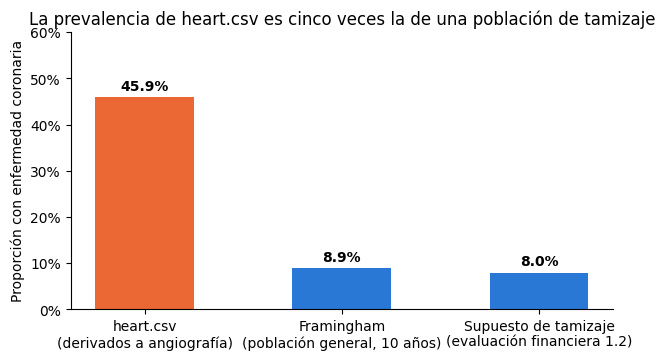

In [16]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

referencias = pd.Series({
    "heart.csv\n(derivados a angiografía)": limpio.enfermedad.mean(),
    "Framingham\n(población general, 10 años)": 0.089,
    "Supuesto de tamizaje\n(evaluación financiera 1.2)": 0.08,
})

fig, ax = plt.subplots(figsize=(7, 3.6))
barras = ax.bar(referencias.index, referencias.values, color=["#eb6834", "#2a78d6", "#2a78d6"], width=.5)
for b, v in zip(barras, referencias.values):
    ax.text(b.get_x() + b.get_width() / 2, v + .015, f"{v:.1%}", ha="center", fontweight="bold")
ax.set_ylim(0, .6); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Proporción con enfermedad coronaria")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("La prevalencia de heart.csv es cinco veces la de una población de tamizaje")
plt.savefig("resultados/fig_prevalencia_tamizaje.png", bbox_inches="tight"); plt.show()

La prevalencia de heart.csv es 45,9 %: casi uno de cada dos pacientes tiene enfermedad coronaria. En una población de tamizaje la proporción es cercana al 8 %. Es el supuesto de la evaluación financiera (1.2), y en Framingham, que sigue a población general, el 8,9 % presenta un evento coronario en 10 años.

La diferencia se explica porque todos los pacientes de heart.csv fueron derivados a angiografía: un médico ya sospechaba enfermedad. La etiqueta solo existe para quien pasó ese filtro, y eso es el sesgo de verificación. Un modelo entrenado con estos datos aprende a distinguir enfermos entre personas que ya parecían enfermas, no entre la población general que llega a un control preventivo.

La consecuencia práctica es el valor predictivo positivo. Con la misma sensibilidad y especificidad, el modelo genera muchas más falsas alarmas cuando la prevalencia baja de 46 % a 8 % (ver auditoría, apartado de VPP).

La prevalencia por sexo (25 % en mujeres, 56 % en hombres) y la tendencia por edad van en la dirección que indica la epidemiología. El tramo de 65 a 77 años baja a 48,8 %, pero tiene solo 41 pacientes, así que no permite concluir.

Nota: Framingham mide incidencia a 10 años y heart.csv mide prevalencia al momento del examen. No son la misma medida, pero ambas indican el orden de magnitud esperable fuera de un hospital.

In [17]:
requeridas = {
    "Identificador de paciente":        None,
    "Edad":                             "age",
    "Sexo":                             "sex",
    "Presión arterial":                 "trestbps",
    "Colesterol total":                 "chol",
    "Glicemia (valor continuo)":        None,
    "Tabaquismo":                       None,
    "Actividad física":                 None,
    "Índice de masa corporal":          None,
    "Diabetes diagnosticada":           None,
    "Uso de antihipertensivos":         None,
    "Evento coronario en seguimiento":  None,
}

chequeo = pd.DataFrame({
    "columna en heart.csv": [c if c else "—" for c in requeridas.values()],
    "¿está?": ["Sí" if c else "NO" for c in requeridas.values()],
}, index=requeridas.keys())
chequeo

,columna en heart.csv,¿está?
Identificador de paciente,—,NO
Edad,age,Sí
Sexo,sex,Sí
Presión arterial,trestbps,Sí
Colesterol total,chol,Sí
Glicemia (valor continuo),—,NO
Tabaquismo,—,NO
Actividad física,—,NO
Índice de masa corporal,—,NO
Diabetes diagnosticada,—,NO


In [18]:
print("Valores de fbs:", sorted(limpio.fbs.unique()))
print(f"Pacientes con glicemia en ayunas > 120 mg/dl: {limpio.fbs.mean():.1%}")

Valores de fbs: [np.int64(0), np.int64(1)]
Pacientes con glicemia en ayunas > 120 mg/dl: 14.5%


In [19]:
# ¿Hay pares de pacientes casi iguales que podrían ser la misma persona con un dato distinto?
X = limpio.drop(columns=["target", "enfermedad"]).values
max_coincidencias = max((X[i] == X[i+1:]).sum(axis=1).max() for i in range(len(X) - 1))
print(f"Máximo de variables coincidentes entre dos pacientes distintos: {max_coincidencias} de {X.shape[1]}")

Máximo de variables coincidentes entre dos pacientes distintos: 10 de 13


De doce variables que necesita un modelo de tamizaje cardiovascular, heart.csv tiene cuatro. Faltan:

Tabaquismo y actividad física, los principales factores de riesgo que una persona puede modificar. Sin ellos, el modelo atribuye su efecto a la edad y al sexo, y termina penalizando atributos demográficos en vez de conductas que se pueden cambiar.
Glicemia como valor continuo. fbs solo indica si supera 120 mg/dl (≈15 % de los pacientes), así que se pierde la diferencia entre 125 y 300 mg/dl.
IMC, diabetes diagnosticada y uso de antihipertensivos, que se registran en cualquier control de salud.
Un evento en el seguimiento. La etiqueta es el diagnóstico al momento de la angiografía, no si la persona tuvo un infarto en los años siguientes. Un modelo así detecta enfermedad presente, no riesgo futuro.
Identificador de paciente. Ningún par de pacientes coincide en más de 10 de las 13 variables, así que no hay indicios de duplicados ocultos. Pero sin un identificador eso no se puede confirmar, y tampoco se puede garantizar que la partición entre entrenamiento y prueba separe personas y no solo filas.

Ninguno de estos problemas se resuelve limpiando: hay que cambiar de fuente.

In [20]:
from sklearn.model_selection import train_test_split

mujeres = limpio[limpio.sex == 0]
print(f"Pacientes: {len(limpio)}")
print(f"Mujeres: {len(mujeres)} ({len(mujeres)/len(limpio):.1%}), con enfermedad: {int(mujeres.enfermedad.sum())}")
print(f"Edad: {limpio.age.min()}–{limpio.age.max()} años | 70 o más: {(limpio.age >= 70).sum()} | sobre 77: {(limpio.age > 77).sum()}")

# Lo que quedaría para evaluar con una partición 70/30
_, prueba = train_test_split(limpio, test_size=.3, random_state=42, stratify=limpio.enfermedad)
m_prueba = prueba[prueba.sex == 0]
print(f"\nConjunto de prueba: {len(prueba)} pacientes | mujeres: {len(m_prueba)} | mujeres con enfermedad: {int(m_prueba.enfermedad.sum())}")

Pacientes: 296
Mujeres: 95 (32.1%), con enfermedad: 24
Edad: 29–77 años | 70 o más: 10 | sobre 77: 0

Conjunto de prueba: 89 pacientes | mujeres: 33 | mujeres con enfermedad: 8


Después de la limpieza quedan 296 pacientes. Las mujeres son un tercio y solo 24 tienen enfermedad. Al reservar el 30 % para evaluar, el conjunto de prueba queda con 8 mujeres enfermas: con eso no se puede estimar la sensibilidad del modelo en mujeres con un intervalo de confianza útil, y la equidad por sexo no se puede auditar.

Tampoco hay pacientes sobre 77 años y solo 10 tienen 70 o más, justo el grupo de mayor riesgo cardiovascular. El modelo no tendría con qué aprender de ellos.

In [21]:
bitacora = pd.DataFrame([
    ["Duplicados",             1025, 302, "Eliminar copias exactas"],
    ["Etiqueta invertida",      302, 302, "enfermedad = 1 - target"],
    ["Faltantes enmascarados",  302, 296, "ca=4 y thal=0 a nulos; excluir 6 registros"],
    ["Fuga de datos",           296, 296, "Quedan 7 predictores de atención primaria"],
], columns=["Paso", "Filas antes", "Filas después", "Decisión"])
bitacora

,Paso,Filas antes,Filas después,Decisión
0,Duplicados,1025,302,Eliminar copias exactas
1,Etiqueta invertida,302,302,enfermedad = 1 - target
2,Faltantes enmascarados,302,296,ca=4 y thal=0 a nulos; excluir 6 registros
3,Fuga de datos,296,296,Quedan 7 predictores de atención primaria


Burleigh, T. (2020, 20 de marzo). Exploring and modeling the Heart Disease UCI dataset. https://tylerburleigh.com/blog/2020/03/20

Detrano, R., Janosi, A., Steinbrunn, W., Pfisterer, M., Schmid, J., Sandhu, S., Guppy, K., Lee, S. y Froelicher, V. (1989). International application of a new probability algorithm for the diagnosis of coronary artery disease. American Journal of Cardiology, 64(5), 304–310.

Lapp, D. (2019). Heart Disease Dataset [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset